# Visualizing fire scars through false color

Author: Emalia Partlow

GitHub repository link: [https://github.com/emaliap/eds220-hwk4.git]()

### About

**Purpose:**

This notebook creates a map visualizing the fire boundaries and the false color image of fires scars for the Eaton and Palisades Fires.

**Highlights:** 

1. Data exploration
2. True color image map of the fire area
3. False color image map of the fire area
3. Final map including the fire boundaries and a false color image highlighting fire scars

**About the data:** 

1. The false color image fire scars data, `landsat8-2025-02-23-palisades-eaton.nc`, includes values of surface reflectance bands (red, green, blue, near-infrared and shortwave infrared). These data were collected by the Landsat 8 satellite.
2. The fire boundary data, `Eaton_Perimeter_20250121.shp` and `Palisades_Perimieter_20250121.shp`, includes polygons of the fire burn perimeters. These data were collected by CAL FIRE.

**References:**

Planetary Computer. (1982 – Present). Landsat Collection 2 (Level-2). Microsoft. [10.5066/P9OGBGM6]()

CAL FIRE (2025). Palisades and Eaton Dissolved Fire Perimeters. ArcGIS Hub. [https://hub.arcgis.com/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about]()

In [32]:
import os
import pandas as pd
import geopandas as gpd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

## Fire perimeter data exploration

The Eaton and Palisades shape files each contain 1 row containing the multipolygon for the fire's boundary. These data are geographic with a CRS of EPSG:4269 

In [2]:
# Import boundary data for the Eaton fire
fp_eaton = os.path.join('data', 'Eaton_Perimeter_20250121', 'Eaton_Perimeter_20250121.shp')
eaton = gpd.read_file(fp_eaton) 
eaton

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LAC,EATON,Heat Perimeter,00009087,{72660ADC-B5EF-4D96-A33F-B4EA3740A4E3},2025-01-08T00:00:00Z,...,14056.26,None,None,None,None,000a99c2-0fef-4960-a3c4-f2342a0cd291,2020-2025,0.005564,0.859026,"MULTIPOLYGON (((-118.10093 34.16680, -118.1008..."


In [3]:
# Print Eaton CRS
eaton.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [4]:
# Import boundary data for the Palisades fire
fp_palisades = os.path.join('data', 'Palisades_Perimieter_20250121', 'Palisades_Perimieter_20250121.shp')
palisades = gpd.read_file(fp_palisades) 
palisades

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LDF,PALISADES,Heat Perimeter,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07T00:00:00Z,...,23448.88,None,None,None,None,8aea8178-a9d8-4c10-a7fd-d1371091b114,2020-2025,0.009268,1.157614,"MULTIPOLYGON (((-118.51974 34.02996, -118.5198..."


In [ ]:
# Print Palisades CRS
palisades.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

## NetCDF data import and exploration

The landsat data are contained in an xarray dataset. The dimensions are: (y: 1418, x: 2742). The coordinates are: x, y, and time. The variables are: red, green, blue, nir08, swir22, and spatial_ref.

In [6]:
# Import landsat data
landsat = xr.open_dataset('data/landsat8-2025-02-23-palisades-eaton.nc')
landsat


<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

## Restoring geospatial information

In [ ]:
# Check if the landsat xarray is a geospatial object
print('landsat xarray CRS: ', landsat.rio.crs)

CRS:  None


In [11]:
# Access the landsat geospatial information stored in the spatial_ref variable
print('landsat CRS stored in spatial_ref: ', landsat.spatial_ref.crs_wkt)

landsat CRS stored in spatial_ref:  PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


In [ ]:
# Recover geospatial information for landsat xarray
landsat.rio.write_crs('EPSG:32611', inplace=True)
print('Updated landsat xarray CRS: ', landsat.rio.crs)

landsat xarray CRS:  EPSG:32611


## True color image

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


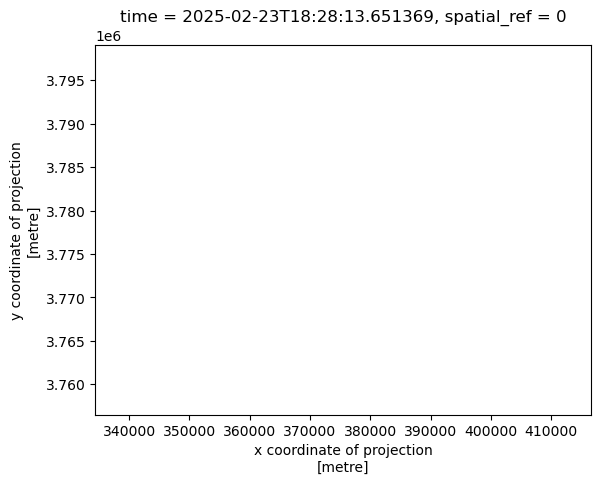

In [ ]:
# Create an RGB image
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow()

/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


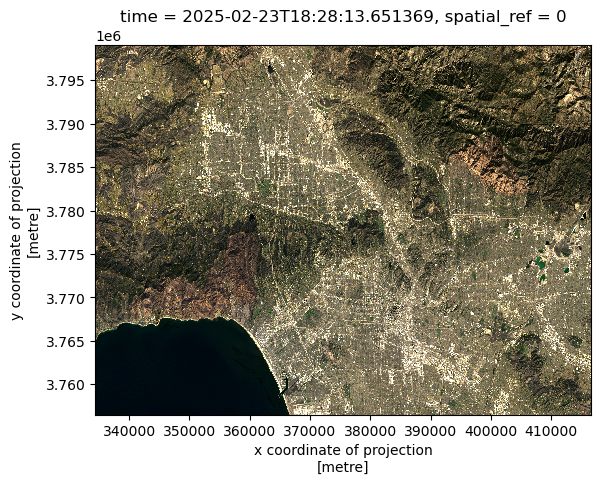

In [ ]:
# Adjust scale used for plotting, ignoring extreme values
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust=True)

In [27]:
# Identify which bands have nan values
np.isnan(landsat[['red', 'green', 'blue', 'nir08', 'swir22']]).sum()

<xarray.Dataset> Size: 56B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          int64 8B 0
    green        int64 8B 1
    blue         int64 8B 109
    nir08        int64 8B 0
    swir22       int64 8B 0

In [30]:
# Replace nan values with 0 and check it worked
landsat = landsat.fillna(0)
np.isnan(landsat[['red', 'green', 'blue', 'nir08', 'swir22']]).sum()

<xarray.Dataset> Size: 56B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          int64 8B 0
    green        int64 8B 0
    blue         int64 8B 0
    nir08        int64 8B 0
    swir22       int64 8B 0

Text(0.5, 1.0, 'True color image of the Eaton and Palisades Fire scars')

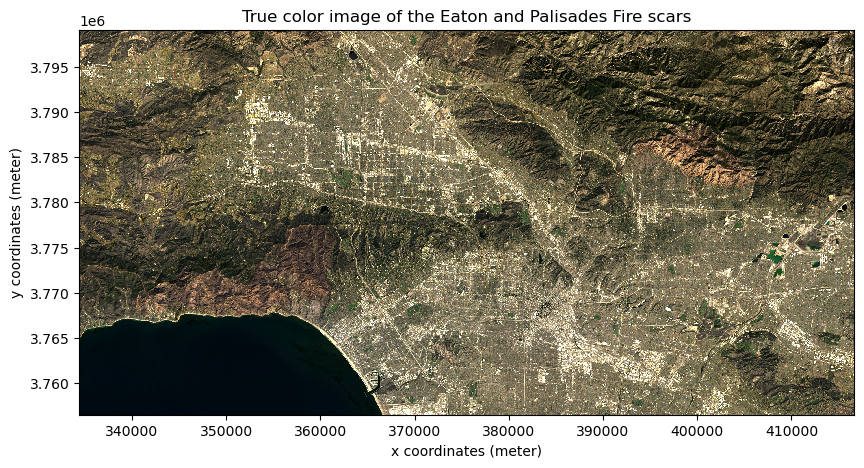

In [ ]:
# Plot new true color image
fig, ax = plt.subplots(figsize=(10,5))

landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust=True)

plt.xlabel('x coordinates (meter)')
plt.ylabel('y coordinates (meter)')
plt.title('True color image of the Eaton and Palisades Fire scars')

plt.show()

The output for the initial attempt at creating a true color image was a blank figure with multiple warnings. After removing na values and adjusting the scale bar, we can see the true color image of the fire scars without warnings.

## False color image

Text(0.5, 1.0, 'False color image of the Eaton and Palisades Fire scars')

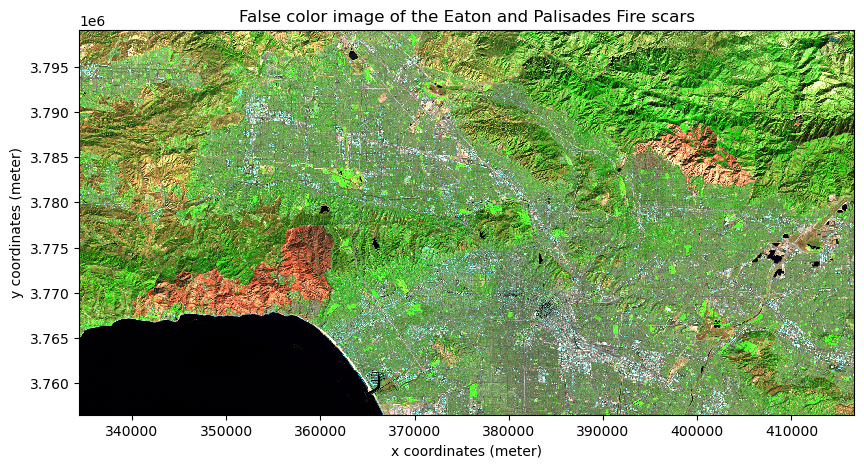

In [ ]:
# Plot new false color image
fig, ax = plt.subplots(figsize=(10,5))

landsat[['swir22', 'nir08', 'red']].to_dataarray().plot.imshow(robust=True)

plt.xlabel('x coordinates (meter)')
plt.ylabel('y coordinates (meter)')
plt.title('False color image of the Eaton and Palisades Fire scars')

plt.show()

## Map

In [39]:
# Reproject CRSs of eaton and palisades perimeters to match landsat
eaton.to_crs('EPSG:32611', inplace=True)
palisades.to_crs('EPSG:32611', inplace=True)

# Check that all dataframes have matching CRSs 
assert eaton.crs == palisades.crs
assert eaton.crs == landsat.rio.crs

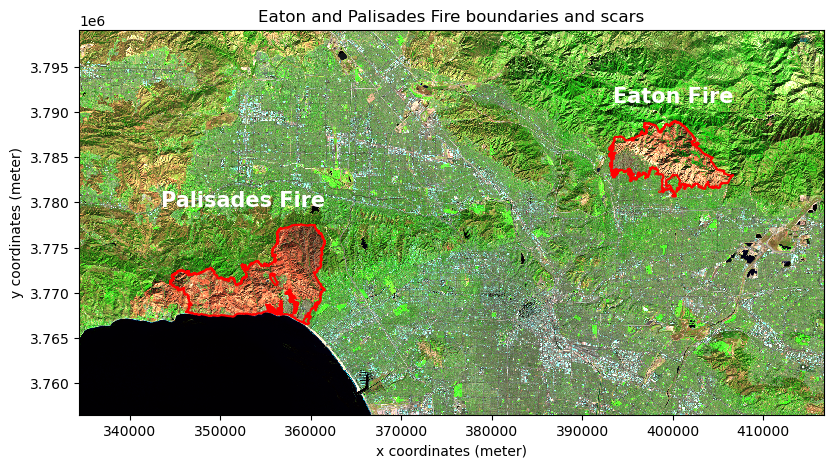

In [54]:
# Plot new false color image
fig, ax = plt.subplots(figsize=(10,5))

# False color image of fire scars
landsat[['swir22', 'nir08', 'red']].to_dataarray().plot.imshow(robust=True)

# Eaton fire boundary
eaton.boundary.plot(ax=ax,
                    color='red')

# Palisades fire boundary
palisades.boundary.plot(ax=ax,
                        color='red')

# Add labels for fire bounaries
ax.text(eaton.geometry.get_coordinates().max().iloc[0], eaton.geometry.get_coordinates().max().iloc[1]+2000, 'Eaton Fire', fontsize=15, fontweight='bold', color='white', ha='right')
ax.text(palisades.geometry.get_coordinates().max().iloc[0], palisades.geometry.get_coordinates().max().iloc[1]+2000, 'Palisades Fire', fontsize=15, fontweight='bold', color='white', ha='right')

plt.xlabel('x coordinates (meter)')
plt.ylabel('y coordinates (meter)')
plt.title('Eaton and Palisades Fire boundaries and scars')

plt.show()

The map displays the boundaries of the Eaton and Palisades Fires, with bold red lines, that occured in LA county during January, 2025. The underlying false color image visualizes the extent of the resulting fire scars. Burned areas reflect shortwave infrared wavelengths, which were assigned to the red channel in the image. Healthy vegetation reflects near-infrared wavelengths, which were assigned to the green channel in the image. 